# 03 - Submission
Membuat `submission.csv` dari model terlatih (`models/pipeline_model_lgbm.pkl`) dan memeriksa formatnya sebelum diupload ke Kaggle.
Jalankan `python train.py` (di folder `scripts/`) lebih dulu agar model tersedia.

In [1]:
import sys, warnings
sys.path.append("../scripts")
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import predict

## 1. Hasilkan submission

In [2]:
predict.generate_submission(
    test_path="../data/test.csv",
    model_path="../models/pipeline_model_lgbm.pkl",
    submission_output_path="../submissions/submission.csv",
)

Memuat data test dan model...
Membuat prediksi...
Submission disimpan di: ../submissions/submission.csv
damage_grade
1    0.095
2    0.122
3    0.199
4    0.252
5    0.333
Name: proportion, dtype: float64


## 2. Validasi format

In [3]:
sub = pd.read_csv("../submissions/submission.csv", dtype={"building_id": str})
sample = pd.read_csv("../data/sample_submission.csv", dtype={"building_id": str})
test = pd.read_csv("../data/test.csv", dtype={"building_id": str})

print("Shape submission     :", sub.shape)
print("Kolom sama dgn sample:", list(sub.columns) == list(sample.columns))
print("Jumlah baris = test  :", len(sub) == len(test))
print("building_id sama dgn sample:", set(sub["building_id"]) == set(sample["building_id"]))
print("Urutan building_id sama     :", len(sub) == len(sample)
      and bool((sub["building_id"].values == sample["building_id"].values).all()))
print("Nilai damage_grade   :", sorted(sub["damage_grade"].unique().tolist()))
print("Missing value        :", int(sub.isna().sum().sum()))
sub.head()

Shape submission     : (228629, 2)
Kolom sama dgn sample: True
Jumlah baris = test  : True
building_id sama dgn sample: True
Urutan building_id sama     : True
Nilai damage_grade   : [1, 2, 3, 4, 5]
Missing value        : 0


,building_id,damage_grade
0,122207000141,2
1,284909000871,5
2,241904000231,4
3,248308000891,2
4,300405002981,4


## 3. Distribusi prediksi vs distribusi train

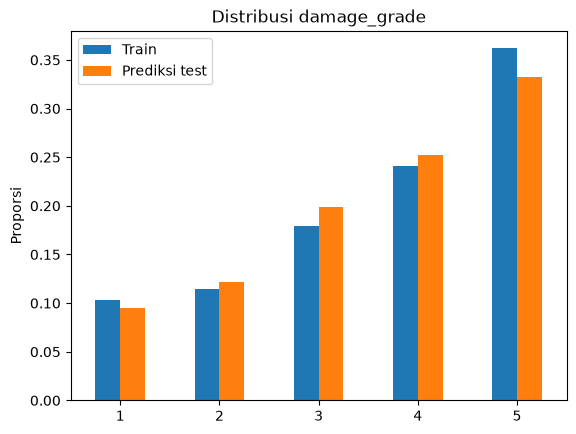

In [4]:
train = pd.read_csv("../data/train.csv", usecols=["damage_grade"])
train_dist = train["damage_grade"].str.extract(r"(\d)")[0].astype(int).value_counts(normalize=True).sort_index()
pred_dist = sub["damage_grade"].value_counts(normalize=True).sort_index()

pd.DataFrame({"Train": train_dist, "Prediksi test": pred_dist}).plot.bar(rot=0)
plt.title("Distribusi damage_grade"); plt.ylabel("Proporsi"); plt.show()

## 4. Upload ke Kaggle
Upload `submissions/submission.csv` lewat tab **Submit Prediction**, atau via CLI:

```
kaggle competitions submit -c structural-damage-classification -f submissions/submission.csv -m "lgbm + fitur tetangga id, tuned, macro-optimized"
```

Hasil Public Score: **0.59886** (macro F1).